# Getting started with longitudinal normative modelling

A normative model tells you where a single scan sits relative to a reference population (a z-score). With two or more visits per subject, we can ask a further question:

> Did this subject change *more than expected* between visits?

That we call **Longitudinal Normative Modelling (LNM)**.

## What you need

1. **Longitudinal data**: at least two scans per person. Here: the LNM dataset (`LNM_data.csv`), loaded with `load_lnm()`.
2. **A correlation matrix** (used for velocity models): load a precomputed one (recommended, used here) or estimate one from your own longitudinal data (needs thousands of subjects with longitudinal data).
3. **A normative model**: fit your own, or transfer a pretrained one from [SURFdrive](https://surfdrive.surf.nl/s/Mb6mZyFmJeCaPcZ?dir=/zip).


## What you will learn

- what a longitudinal dataset and a correlation matrix look like,
- how to compute **z-diff** and **z-gain (velocity model)**, and whether they agree,
- when to use which score,
- how to plot **thrivelines** on normative centiles.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import pcntoolkit.util.output
from pcntoolkit import (
    CorrelationMatrix,
    VelocityModel,
    ZDiffScore,
    fetch_example_correlation_matrix,
    load_lnm,
)
from pcntoolkit.util.plotter import plot_thrivelines

# Hide PCNtoolkit's "Process: ..." progress messages
pcntoolkit.util.output.Output.set_show_messages(False)

# Right middle frontal gyrus thickness: the region the example correlation
# matrix covers.
REGION = "rh_G_front_middle_thickness"
CENTILES = [0.05, 0.25, 0.5, 0.75, 0.95]

## 1. The longitudinal data

Our example dataset (`LNM_data.csv`) has cortical thickness for healthy controls and patients with early-stage schizophrenia, each scanned twice about a year apart ([Rehák Bučková et al., 2025](https://doi.org/10.7554/eLife.95823)).

In [2]:
lnm = load_lnm()
lnm.to_dataframe()[["subject_ids", "visits", "X", "batch_effects"]].head()

subject_ids visits       X batch_effects         
             subject_ids  visit     age           sex     site
observations                                                  
0                   C000      1  39.377             M  NIMH-CZ
1                   C001      1  30.666             M  NIMH-CZ
2                   C002      1  34.160             M  NIMH-CZ
3                   C003      1  26.474             F  NIMH-CZ
4                   C004      1  25.764             M  NIMH-CZ

In [3]:
subject_ids = lnm.get_subject_ids()
ages = lnm.X.sel(covariates="age").values

print(f"Subjects:             {len(np.unique(subject_ids))}")
print(f"Visits per subject:   {int(lnm.get_visits().max())}")
print(f"Age range:            {ages.min():.0f} to {ages.max():.0f} years")
print(f"Brain regions:        {lnm.sizes['response_vars']}")

Subjects:             165
Visits per subject:   2
Age range:            18 to 55 years
Brain regions:        185


Now load controls and patients separately. We keep one region because the example correlation matrix covers only that one.

In [4]:
controls = load_lnm(group="control").sel(response_vars=[REGION])
patients = load_lnm(group="patient").sel(response_vars=[REGION])

## 2. Fit and transfer a normative model

Longitudinal modelling starts from an ordinary normative model, so we build one first, exactly as in the earlier tutorials. Any normative model works. Here we fit a BLR model on fcon1000 and then transfer it to the LNM site, which the model has never seen.

In [5]:
from pcntoolkit import BLR, NormativeModel, load_fcon1000
from pcntoolkit.math_functions.basis_function import BsplineBasisFunction

# Fit on fcon1000
fcon1000 = load_fcon1000().sel(response_vars=[REGION])
fcon1000_model = NormativeModel(
    BLR(
        basis_function_mean=BsplineBasisFunction(degree=3, nknots=5),
        warp_name="warpsinharcsinh",
    ),
    inscaler="standardize",
    outscaler="standardize",
    savemodel=False,
    saveresults=False,
    saveplots=False,
)
fcon1000_model.fit(fcon1000)

In [6]:
# Get the controls' subject IDs and visit numbers
control_subjects = controls.get_subject_ids()
control_visits = controls.get_visits()

# Randomly pick 20% of the controls for the adaptation group
all_controls = np.unique(control_subjects)
rng = np.random.default_rng(42)
adaptation_people = rng.choice(all_controls, size=int(0.2 * len(all_controls)), replace=False)

# True for every scan of a control subject in the adaptation group
in_adaptation_group = np.isin(control_subjects, adaptation_people)

# Select adaptation controls only from visit 1 because visit 2 is highly correlated 
# with visit 1, so it adds no new information for the adaptation
adapt_controls = controls.isel(observations=in_adaptation_group & (control_visits == 1))
reference_controls = controls.isel(observations=~in_adaptation_group)

print(f"Adaptation group: {len(adaptation_people)} people, visit 1 only")
print(f"Reference group:  {len(all_controls) - len(adaptation_people)} people, both visits")

Adaptation group: 13 people, visit 1 only
Reference group:  54 people, both visits


In [7]:
# Adapt/transfer the fcon1000 model to the LNM site
lnm_model = fcon1000_model.transfer(adapt_controls)

# Get a z-score for every visit of the reference controls and the patients
lnm_model.predict(reference_controls)
lnm_model.predict(patients);

## 3. Load the correlation matrix

Velocity models (z-gain scores and thrivelines) need a correlation matrix (how strongly do z-scores correlate between two timepoints). In the loaded correlation matrix the timepoints are ages.

A reliable matrix needs thousands of people scanned repeatedly, so we recommend reusing a precomputed one. The one we use in this tutorial was estimated by [Bayer et al. (2026)](https://arxiv.org/abs/2601.07591) in thousands of subjects, each scanned two or more times. 

Note that the correlation matrix does not have to come from the same data as your normative model.

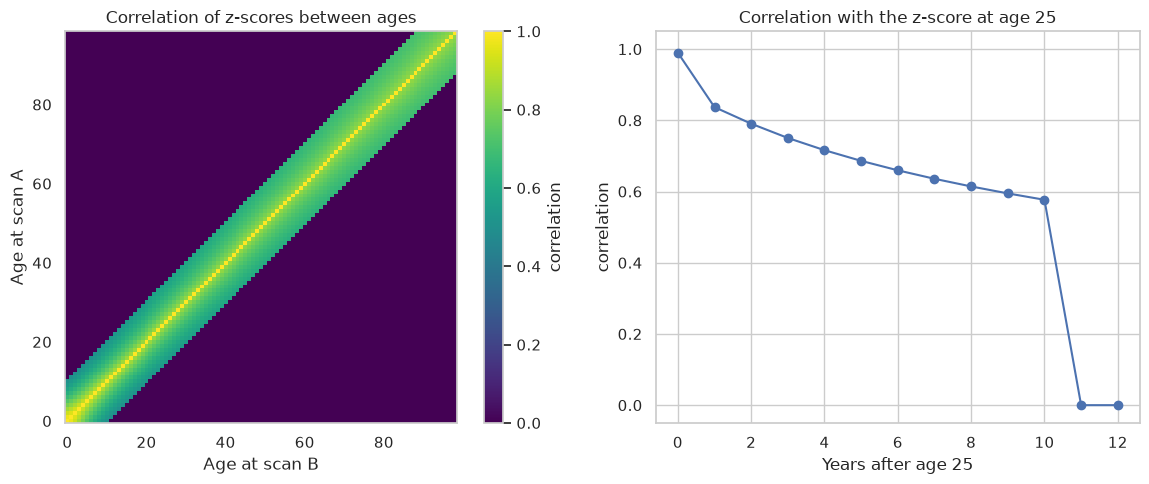

In [8]:
# Download the example correlation matrix from GitHub
corr_path = fetch_example_correlation_matrix()
# Load the correlation matrix from the downloaded CSV
corr = CorrelationMatrix.load(corr_path)
matrix = corr.matrix.sel(response_vars=REGION)

age = 25
gaps = np.arange(0, 13)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1.1, 1]})
image = axes[0].imshow(matrix.values, origin="lower", cmap="viridis", vmin=0, vmax=1)
axes[0].set_xlabel("Age at scan B")
axes[0].set_ylabel("Age at scan A")
axes[0].set_title("Correlation of z-scores between ages")
axes[0].grid(False)
fig.colorbar(image, ax=axes[0], label="correlation")

# CorrelationMatrix.get_correlation() reads a correlation between two specific timepoints for one response variable.
axes[1].plot(gaps, [corr.get_correlation(REGION, age, age + gap) for gap in gaps], marker="o")
axes[1].set_xlabel(f"Years after age {age}")
axes[1].set_ylabel("correlation")
axes[1].set_title(f"Correlation with the z-score at age {age}")
axes[1].set_ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

We see that the correlations are strongest on the diagonal and fade as scans get further apart in time. 

Also we see that the matrix only holds correlations for scans up to 10 years apart and sets everything beyond that to 0. The two visits in our `LNM_data.csv` are about a year apart, well within that range.

## 4. z-diff vs z-gain

Both scores ask whether a person's change between visits is unusual. Values near 0 are typical; large positive or negative values flag unusual change.

### z-diff

*z-diff* ([Rehák Bučková et al., 2025](https://doi.org/10.7554/eLife.95823)) quantifies the longitudinal change in a brain measure relative to what would be expected based on healthy ageing,  divided by how much this change typically varies in healthy controls. It needs a BLR model and only two visits per subject.

In the diagram below you see the z-diff score for our tutorial's data (two visits per subject):

![Fig. 1: z-diff score](../doc/_static/zdiff.png)

Kudos to Barbora Rehák Bučková for making this beautiful figure ([Rehák Bučková et al., 2025](https://doi.org/10.7554/eLife.95823)).

### z-gain

*z-gain* ([Bayer et al., 2026](https://arxiv.org/abs/2601.07591)) asks whether the later z-score is surprising given the earlier one based on the knowledge coming from the correlation matrix. It works with any model and any number of visits.

In the diagram below you see the velocity model (z-gain score and thrivelines) for our tutorial's data (two visits per subject):

![Fig. 2: Velocity model](../doc/_static/zgain.svg)

In the z-gain figure the first rows are the same as for z-diff because both methods require longitudinal data and a fitted normative model.

### Which score should I use?

| You have… | Use |
|---|---|
| Two visits, BLR or warped-BLR model | `ZDiffScore` or `VelocityModel` |
| Want thrivelines | `VelocityModel` |
| Three or more visits | `VelocityModel` |
| HBR model | `VelocityModel` |

### Computing the scores

Both methods work in two steps:

1. **Create the object** with what stays the same for everyone: the normative model, plus the information that defines how much change between visits is normal (z-diff: the held-out controls; velocity model: the correlation matrix). Nothing is computed yet.
2. **Call `.score(data)`** on the people you want to score. `ZDiffScore.score()` returns z-diff; `VelocityModel.score()` returns z-gain.

`VelocityModel` can do more than just scoring. For example, we can compute thrivelines.

In [9]:
# Create the ZDiffScore object
zdiff = ZDiffScore(lnm_model, reference_data=reference_controls)

# Compute zdiff for the patients
zdiff_patients = zdiff.score(patients)
# Display the first few z-diff scores for the specified region
zdiff_patients.sel(response_vars=REGION).to_series().head()

subjects
P000   -0.479059
P001   -2.467373
P002   -0.186780
P003    0.990796
P004   -0.404522
Name: zdiff, dtype: float64

In [10]:
# Create the VelocityModel object
velocity = VelocityModel(lnm_model, corr)

# Compute z-gain for the patients
zgain_patients = velocity.score(patients)
# Display the first few z-gain scores for the specified region
zgain_patients.sel(response_vars=REGION).to_series().head()

subjects
P000   -0.060133
P001   -2.685842
P002   -0.296639
P003    0.673875
P004    0.183253
Name: zgain, dtype: float64

To compare the two scores, we also score the held-out controls and put everything in one table.

In [11]:
control_scores = pd.DataFrame(
    {
        "z_diff": zdiff.score(reference_controls).sel(response_vars=REGION).to_series(),
        "z_gain": velocity.score(reference_controls).sel(response_vars=REGION).to_series(),
        "group": "control",
    }
)
patient_scores = pd.DataFrame(
    {
        "z_diff": zdiff_patients.sel(response_vars=REGION).to_series(),
        "z_gain": zgain_patients.sel(response_vars=REGION).to_series(),
        "group": "patient",
    }
)
scores = pd.concat([control_scores, patient_scores])
scores.head()

,z_diff,z_gain,group
subjects,,,
C000,0.965918,0.685298,control
C001,-1.025966,-0.749019,control
C002,1.261810,0.143184,control
C003,-1.307466,-0.318350,control
C007,0.869395,0.045803,control


### Do z-diff and z-gain agree?

Does a person with an extreme z-diff also have an extreme z-gain? Here we call a score *extreme* when it is beyond ±1.96 (dashed lines).

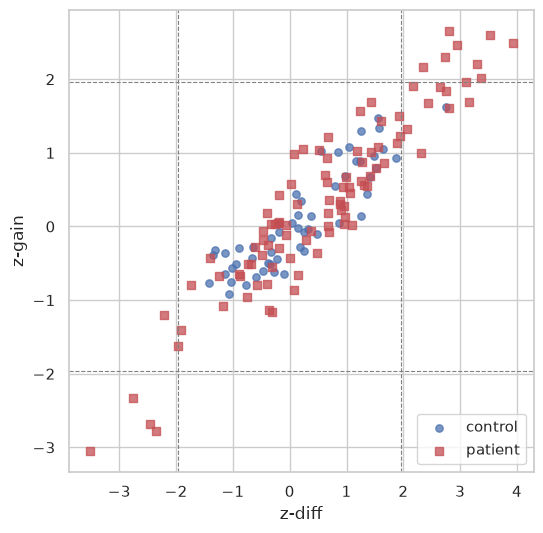

Spearman correlation: 0.90


,extreme on both,extreme on z-diff only,extreme on z-gain only
group,,,
control,0,1,0
patient,13,10,0


In [12]:
fig, ax = plt.subplots(figsize=(6, 6))
for group_name, color, marker in [("control", "#4c72b0", "o"), ("patient", "#c44e52", "s")]:
    group_scores = scores[scores["group"] == group_name]
    ax.scatter(group_scores["z_diff"], group_scores["z_gain"], s=28, alpha=0.75,
               color=color, marker=marker, label=group_name)
for threshold in [-1.96, 1.96]:
    ax.axvline(threshold, color="grey", ls="--", lw=0.8)
    ax.axhline(threshold, color="grey", ls="--", lw=0.8)
ax.set_xlabel("z-diff")
ax.set_ylabel("z-gain")
ax.legend()
plt.show()

rho, _ = stats.spearmanr(scores["z_diff"], scores["z_gain"])
print(f"Spearman correlation: {rho:.2f}")

# Count, per group, how many people each score calls extreme (beyond ±1.96)
extreme_z_diff = scores["z_diff"].abs() > 1.96
extreme_z_gain = scores["z_gain"].abs() > 1.96
pd.DataFrame(
    {
        "extreme on both": (extreme_z_diff & extreme_z_gain).groupby(scores["group"]).sum(),
        "extreme on z-diff only": (extreme_z_diff & ~extreme_z_gain).groupby(scores["group"]).sum(),
        "extreme on z-gain only": (~extreme_z_diff & extreme_z_gain).groupby(scores["group"]).sum(),
    }
)

The two scores rank people almost the same way (Spearman correlation: 0.90), and every patient with an extreme z-gain also has an extreme z-diff. z-diff though flags as extreme a few more patients than z-gain.

## 5. Thrivelines

Thrivelines borrow an idea from children's growth charts. Each short blue line starts on a centile and runs one year forward. It shows the largest change (here: decline) a person starting there can have while still changing as expected:

- **staying on or above a thriveline**: normal change,
- **dropping below it**: unusually large decline (z-gain below −1.96).

Below we draw the patient with the most negative z-gain (red) and the control with the most typical change (blue).

`VelocityModel.compute_thrivelines()` computes the thrivelines from the correlation matrix, and `plot_thrivelines()` draws them on the normative model's centile chart.


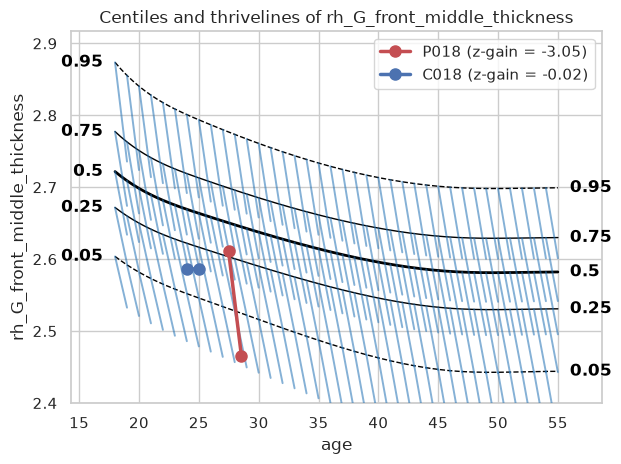

In [13]:
# Get the age range of LNM_data.csv
lnm_ages = lnm.X.sel(covariates="age").values
youngest, oldest = int(lnm_ages.min()), int(lnm_ages.max()) + 1

# Compute thrivelines
thrivelines = velocity.compute_thrivelines(
    centiles=CENTILES,  # thrivelines start on these centile curves
    covariate_range=(youngest, oldest),
    zgain_threshold=-1.96  # -1.96: largest expected decline; +1.96: largest expected increase
)

# Select 2 subjects
declining_patient = scores.loc[scores["group"] == "patient", "z_gain"].idxmin()
typical_control = scores.loc[scores["group"] == "control", "z_gain"].abs().idxmin()

# Plot thrivelines
figs = plot_thrivelines(
    lnm_model,
    thrivelines=thrivelines,
    centiles=CENTILES,
    response_vars=[REGION],
    show_figure=False,
)
# Plot the individual trajectories of the selected subjects over the thrivelines
ax = figs[0].axes[0]
for person, data, color in [
    (declining_patient, patients, "#c44e52"),
    (typical_control, reference_controls, "#4c72b0"),
]:
    is_person = data.get_subject_ids() == person
    ax.plot(
        data.X.sel(covariates="age").values[is_person],
        data.Y.sel(response_vars=REGION).values[is_person],
        color=color, lw=2.5, marker="o", markersize=8, zorder=10,
        label=f"{person} (z-gain = {scores.loc[person, 'z_gain']:.2f})",
    )
ax.legend(loc="best")
plt.show()